# Dataset 3 — NEU Surface Defect Database

**Segunda Verificação Parcial — Aprendizado de Máquina (PPGEP/UFPE)**  
**Problema:** classificação multiclasse de defeitos superficiais em aço laminado.

**Seis classificadores:** CNN, MLP (TensorFlow/Keras + SciKeras), Random Forest, Árvore de Decisão, SVM e Gaussian Naive Bayes. Todos passam por **GridSearchCV e Optuna**, com o mesmo particionamento de validação cruzada. Por algoritmo, comparamos as buscas e escolhemos **somente um** modelo para relatório de classificação e matriz de confusão.

> **Separação essencial:** `train/images` é usado para treinar e para os folds da validação cruzada. A pasta `validation/images` é reservada como **teste final (holdout)**. Não participa de seleção, ajuste ou curvas de aprendizagem. O nome `validation` vem do diretório original, mas aqui sua função metodológica é **teste**.

> **Resolução:** as imagens originais têm 200×200 pixels; para controlar memória da CNN e preservar a arquitetura compacta do Dataset 1, configuramos a entrada dos modelos em **64×64 pixels**. É possível aumentar `MODEL_IMAGE_SIZE`, com custo computacional maior. Os HOGs também são obtidos dessa mesma resolução, para consistência.

## 1. Bibliotecas e configuração

Este notebook foi preparado para execução no **Kaggle Notebooks**, com os arquivos do dataset montados em `/kaggle/input`. Não é necessário usar `ImageDataGenerator` porque as imagens são carregadas como arrays e a validação cruzada é feita explicitamente pelo scikit-learn.

In [ ]:
# Execute uma vez no Kaggle, caso as bibliotecas ainda não estejam disponíveis.
%pip -q install scikeras optuna

In [ ]:
pip install "scikit-learn<1.6.0"

In [ ]:
from pathlib import Path
import os, gc, time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from skimage.feature import hog
from IPython.display import display

SEED = 42
np.random.seed(SEED)
IMAGE_SIZE = (200, 200)       # Dimensão original do NEU-DET
MODEL_IMAGE_SIZE = (64, 64)  # Entrada da CNN e origem dos vetores HOG
BATCH_SIZE = 16
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp'}

print('TensorFlow, SciKeras e Optuna são importados na célula de otimização.')

TensorFlow, SciKeras e Optuna são importados na célula de otimização.


## 2. Localização do dataset e leitura dos rótulos

As **subpastas de cada classe** dentro de `train/images` e `validation/images` já fornecem os rótulos para classificação. Os arquivos XML de localização de defeitos (*bounding boxes*) não são necessários para esta tarefa de **classificação da imagem inteira**.

In [ ]:

import kagglehub
from pathlib import Path

# 1. Baixar ou localizar o dataset pelo KaggleHub
path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Caminho retornado pelo KaggleHub:", path)

# 2. Localizar a pasta que contém train/images e validation/images
BASE_PATH = Path(path)

CANDIDATOS_ROOT = [
    BASE_PATH,
    BASE_PATH / "NEU-DET",
    *BASE_PATH.rglob("NEU-DET")
]

DATA_ROOT = next(
    (
        p for p in CANDIDATOS_ROOT
        if (p / "train" / "images").is_dir()
        and (p / "validation" / "images").is_dir()
    ),
    None
)

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Não encontrei as pastas train/images e validation/images "
        f"dentro de {BASE_PATH}. Verifique a estrutura do dataset."
    )

# 3. Definir os caminhos
TRAIN_DIR = DATA_ROOT / "train" / "images"
TEST_DIR = DATA_ROOT / "validation" / "images"

# Mantém compatibilidade com o restante do notebook
VAL_DIR = TEST_DIR

print("\nDATA_ROOT:", DATA_ROOT)
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

# 4. Identificar as classes
classes = sorted(
    p.name for p in TRAIN_DIR.iterdir() if p.is_dir()
)

if len(classes) != 6:
    raise ValueError(
        f"Esperadas 6 classes; encontradas {len(classes)}: {classes}"
    )

classes_teste = sorted(
    p.name for p in TEST_DIR.iterdir() if p.is_dir()
)

if classes != classes_teste:
    raise ValueError(
        f"Classes não coincidem entre treino e teste: "
        f"{classes} x {classes_teste}"
    )

# 5. Codificação das classes
num_classes = len(classes)

class_to_idx = {
    classe: i for i, classe in enumerate(classes)
}

idx_to_class = {
    i: classe for classe, i in class_to_idx.items()
}

print("\nClasses codificadas:", class_to_idx)


Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Caminho retornado pelo KaggleHub: /kaggle/input/neu-surface-defect-database

DATA_ROOT: /kaggle/input/neu-surface-defect-database/NEU-DET
TRAIN_DIR: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images
TEST_DIR: /kaggle/input/neu-surface-defect-database/NEU-DET/validation/images

Classes codificadas: {'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [ ]:
def catalogar_imagens(diretorio, conjunto):
    registros = []
    for classe in classes:
        pasta = diretorio/classe
        paths = sorted(p for p in pasta.rglob('*')
                       if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        if not paths:
            raise ValueError(f'Nenhuma imagem encontrada em {pasta}')
        for p in paths:
            registros.append({'caminho': str(p), 'classe': classe,
                              'classe_idx': class_to_idx[classe], 'conjunto': conjunto})
    return pd.DataFrame(registros)

df_treino = catalogar_imagens(TRAIN_DIR, 'Treinamento')
df_teste = catalogar_imagens(TEST_DIR, 'Teste final')
df = pd.concat([df_treino, df_teste], ignore_index=True)

print('Total treino:', len(df_treino))
print('Total teste:', len(df_teste))
print('Total geral:', len(df))
display(pd.crosstab(df['classe'], df['conjunto'], margins=True))

# As duas partições não devem conter exatamente o mesmo arquivo.
# Verificação por hash de conteúdo (não detecta duplicatas visualmente similares).
def verificar_duplicatas_cruzadas(df_a, df_b):
    def hash_arquivo(path):
        return hashlib.sha256(Path(path).read_bytes()).hexdigest()
    a = {hash_arquivo(p) for p in df_a['caminho']}
    b = {hash_arquivo(p) for p in df_b['caminho']}
    comuns = a & b
    if comuns:
        raise ValueError(f'Foram encontradas {len(comuns)} imagens idênticas no treino e no teste!')
    print('Checagem SHA256: sem arquivos idênticos entre treino e teste.')

verificar_duplicatas_cruzadas(df_treino, df_teste)

Total treino: 1440
Total teste: 360
Total geral: 1800


conjunto,Teste final,Treinamento,All
classe,,,
crazing,60,240,300
inclusion,60,240,300
patches,60,240,300
pitted_surface,60,240,300
rolled-in_scale,60,240,300
scratches,60,240,300
All,360,1440,1800


Checagem SHA256: sem arquivos idênticos entre treino e teste.


## 3. Análise exploratória — EDA

A contagem por classe permite confirmar o balanceamento **real dos diretórios carregados**. Mostramos exemplos das imagens originais, sem alterar seus rótulos.

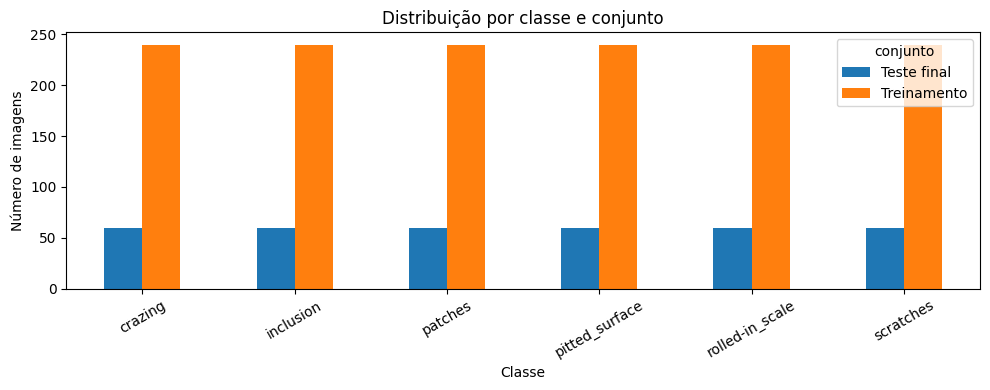

Treino: 1440 imagens | intervalo: 240–240 por classe


,N,%
classe,,
crazing,240,16.67
inclusion,240,16.67
patches,240,16.67
pitted_surface,240,16.67
rolled-in_scale,240,16.67
scratches,240,16.67


Teste: 360 imagens | intervalo: 60–60 por classe


,N,%
classe,,
crazing,60,16.67
inclusion,60,16.67
patches,60,16.67
pitted_surface,60,16.67
rolled-in_scale,60,16.67
scratches,60,16.67


In [ ]:
contagem = pd.crosstab(df['classe'], df['conjunto']).reindex(classes)
fig, ax = plt.subplots(figsize=(10, 4))
contagem.plot(kind='bar', ax=ax)
ax.set(title='Distribuição por classe e conjunto', xlabel='Classe', ylabel='Número de imagens')
ax.tick_params(axis='x', labelrotation=30)
plt.tight_layout()
plt.show()

for nome, sub_df in [('Treino', df_treino), ('Teste', df_teste)]:
    distribuicao = sub_df['classe'].value_counts().reindex(classes)
    print(f'{nome}: {len(sub_df)} imagens | intervalo: {distribuicao.min()}–{distribuicao.max()} por classe')
    display(pd.DataFrame({'N': distribuicao, '%': (100*distribuicao/len(sub_df)).round(2)}))

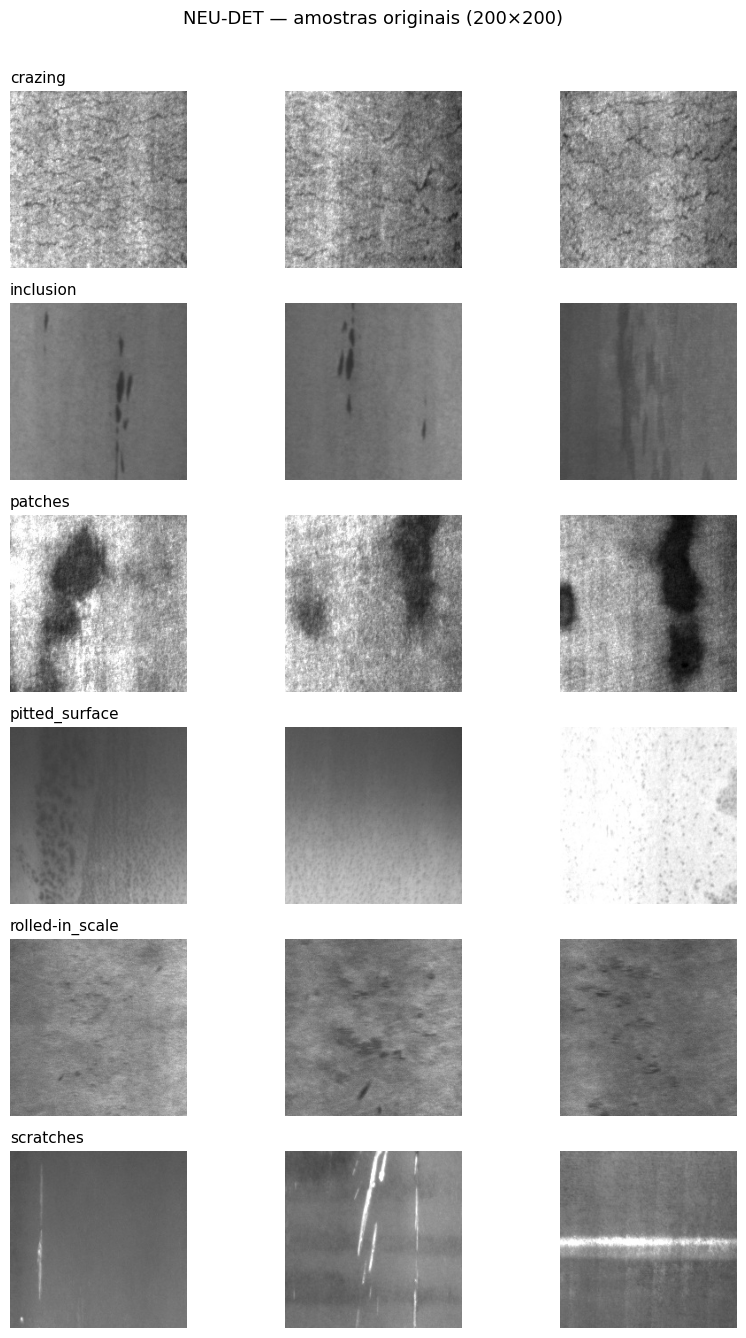

In [ ]:
# Amostras em resolução original, em tons de cinza.
fig, axs = plt.subplots(num_classes, 3, figsize=(9, 2.2*num_classes))
for i, classe in enumerate(classes):
    exemplos = df_treino.loc[df_treino.classe.eq(classe), 'caminho'].iloc[:3]
    for j, caminho in enumerate(exemplos):
        img = cv2.imread(caminho, cv2.IMREAD_GRAYSCALE)
        axs[i, j].imshow(img, cmap='gray', vmin=0, vmax=255)
        axs[i, j].axis('off')
        if j == 0:
            axs[i, j].set_title(classe, loc='left', fontsize=11)
fig.suptitle('NEU-DET — amostras originais (200×200)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

## 4. Pré-processamento para classificação

1. Ler as imagens em **tons de cinza**, como no NEU-DET.
2. Redimensioná-las de 200×200 para `MODEL_IMAGE_SIZE` (64×64 por padrão).
3. Normalizar os pixels para o intervalo **[0, 1]**.
4. CNN recebe o tensor `(N, 64, 64, 1)`; modelos clássicos e MLP recebem vetores **HOG**.
5. `StandardScaler` será ajustado *dentro de cada fold* para SVM e MLP (não antes da validação cruzada).

**Observação:** esta versão do problema é classificação da imagem inteira. Ao contrário do PCB Defect, não são feitos recortes a partir de *bounding boxes*.

In [ ]:
def carregar_matrizes(df_entrada, tamanho=MODEL_IMAGE_SIZE):
    X, y = [], []
    for registro in df_entrada.itertuples(index=False):
        imagem = cv2.imread(registro.caminho, cv2.IMREAD_GRAYSCALE)
        if imagem is None:
            raise ValueError(f'Não foi possível abrir {registro.caminho}')
        imagem = cv2.resize(imagem, tamanho, interpolation=cv2.INTER_AREA)
        X.append(imagem.astype(np.float32) / 255.0)
        y.append(int(registro.classe_idx))
    X = np.asarray(X, dtype=np.float32)[..., np.newaxis]
    y = np.asarray(y, dtype=np.int64)
    return X, y

X_treino_cnn, y_treino_idx = carregar_matrizes(df_treino)
X_teste_cnn, y_teste_idx = carregar_matrizes(df_teste)

assert X_treino_cnn.shape[-1] == 1
assert X_teste_cnn.shape[1:] == X_treino_cnn.shape[1:]
assert set(np.unique(y_treino_idx)) == set(range(num_classes))

print('X_treino_cnn:', X_treino_cnn.shape, '| y_treino:', y_treino_idx.shape)
print('X_teste_cnn: ', X_teste_cnn.shape, '| y_teste: ', y_teste_idx.shape)
print('Pixels treino: min', X_treino_cnn.min(), 'max', X_treino_cnn.max())

X_treino_cnn: (1440, 64, 64, 1) | y_treino: (1440,)
X_teste_cnn:  (360, 64, 64, 1) | y_teste:  (360,)
Pixels treino: min 0.0 max 1.0


In [ ]:
def extrair_hog_dataset(X):
    caracteristicas = [hog(
        img[:, :, 0],
        orientations=8,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        feature_vector=True
    ) for img in X]
    return np.asarray(caracteristicas, dtype=np.float32)

X_treino_hog_raw = extrair_hog_dataset(X_treino_cnn)
X_teste_hog_raw = extrair_hog_dataset(X_teste_cnn)
print('Vetores HOG treino:', X_treino_hog_raw.shape)
print('Vetores HOG teste: ', X_teste_hog_raw.shape)

# Nomes compatíveis com o pipeline anterior, se você os utilizar em análises adicionais.
X_treino_features = X_treino_hog_raw
X_teste_features = X_teste_hog_raw
# Não aplicar StandardScaler aqui: ele será ajustado em cada fold do Pipeline.

Vetores HOG treino: (1440, 288)
Vetores HOG teste:  (360, 288)


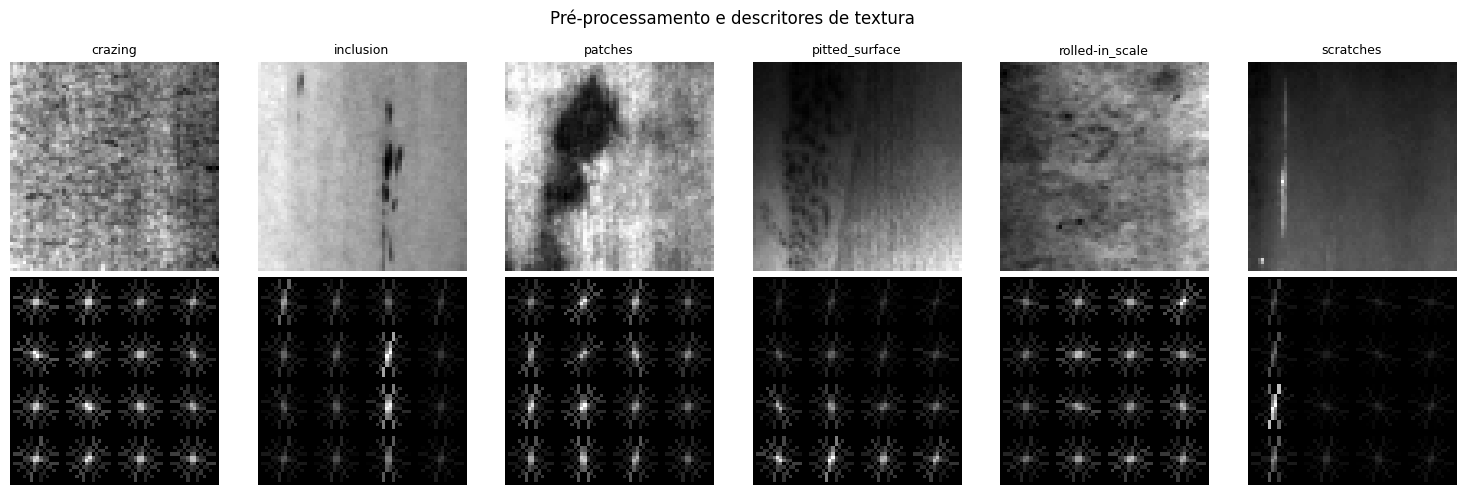

In [ ]:
fig, axs = plt.subplots(2, 6, figsize=(15, 5))
for i, classe in enumerate(classes):
    idx = np.flatnonzero(y_treino_idx == i)[0]
    img = X_treino_cnn[idx, :, :, 0]
    _, imagem_hog = hog(img, orientations=8, pixels_per_cell=(16,16),
                         cells_per_block=(2,2), block_norm='L2-Hys',
                         visualize=True, feature_vector=True)
    axs[0, i].imshow(img, cmap='gray')
    axs[1, i].imshow(imagem_hog, cmap='gray')
    axs[0, i].set_title(classe, fontsize=9)
    for eixo in [axs[0,i], axs[1,i]]:
        eixo.axis('off')
axs[0,0].set_ylabel('Imagem', fontsize=12)
axs[1,0].set_ylabel('HOG', fontsize=12)
plt.suptitle('Pré-processamento e descritores de textura')
plt.tight_layout()
plt.show()

## 5. Experimento — GridSearchCV versus Optuna

**Comparação justa dentro de cada algoritmo:** mesmo conjunto de treinamento, mesmos folds estratificados, mesma métrica principal (**acurácia CV**) e F1 macro como critério complementar. O número de combinações e os espaços explorados pelas ferramentas são informados para contextualizar o tempo.

- **Sem pruning no Optuna:** cada tentativa é avaliada nos três folds completos.
- **Sem usar `validation/images` durante a otimização.**
- Para cada algoritmo, a célula **A** executa as buscas; a célula **B** mostra o quadro comparativo, escolhe o método e faz **uma única** avaliação final.
- Para CNN e MLP, a célula B também apresenta **um par de curvas** (acurácia e perda), obtidas em um ajuste diagnóstico sobre um fold interno, sem utilizar o teste.

In [ ]:
# ============================================================
# CONFIGURAÇÃO COMPARTILHADA — GridSearchCV + Optuna
# ============================================================
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import tensorflow as tf
import gc
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from scikeras.wrappers import KerasClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Conv2D, MaxPooling2D, AveragePooling2D
from tensorflow.keras.optimizers import Adam

# Mantemos os avisos de sklearn/TensorFlow visíveis para depuração.
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
N_SPLITS = 3
N_TRIALS = 10  # Quantidade de tentativas do Optuna em cada algoritmo
SCORING = "accuracy"  # Métrica principal otimizada pelas duas ferramentas.
TOL_ACURACIA_CV = 0.005   # Diferenças até 0,5 ponto percentual: critério de desempate.
TOL_F1_CV = 0.005
PLOTAR_CURVAS_NN = True  # Desative se quiser evitar o ajuste adicional de diagnóstico.

# Permite que o TensorFlow aloque memória da GPU conforme necessário
gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

print("GPUs disponíveis:", gpus)

# O NEU-DET contém imagens independentes (sem os recortes por imagem de origem do PCB).
# Por isso usamos StratifiedKFold, aplicado SOMENTE ao treino do Kaggle.
# Usamos exatamente os mesmos splits nos dois otimizadores.
y_treino_idx = np.asarray(y_treino_idx).astype(int)
y_teste_idx = np.asarray(y_teste_idx).astype(int)
cv_stratified = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(cv_stratified.split(np.zeros(len(y_treino_idx)), y_treino_idx))

# Nomes de classes em ordem numérica, respeitando os dicionários já definidos no notebook.
if "idx_to_class" in globals():
    nomes_classes = [idx_to_class[i] for i in range(num_classes)]
elif "class_to_idx" in globals():
    nomes_classes = [nome for nome, indice in sorted(class_to_idx.items(), key=lambda item: item[1])]
else:
    nomes_classes = [str(i) for i in range(num_classes)]

def executar_buscas(nome, estimador, grade_parametros, sugerir_parametros, X, y, n_trials=N_TRIALS):
    """Compara as buscas nos MESMOS folds estratificados; não usa dados de teste."""
    print(f"\n{'=' * 72}\n{nome}: GridSearchCV\n{'=' * 72}")
    inicio_gs = time.time()
    busca_gs = GridSearchCV(
        estimator=estimador,
        param_grid=grade_parametros,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        refit="accuracy",
        cv=cv_splits,
        n_jobs=1,
        verbose=1,
        error_score="raise"
    )
    busca_gs.fit(X, y)
    tempo_gs = time.time() - inicio_gs  # Inclui ajuste final com todos os dados de treino.
    melhor_idx = busca_gs.best_index_

    print(f"Melhor acurácia média CV (GS): {busca_gs.best_score_:.4f}")
    print("Melhores parâmetros GS:", busca_gs.best_params_)
    print(f"Tempo GS (incluindo refit): {tempo_gs / 60:.2f} min")

    print(f"\n{'=' * 72}\n{nome}: Optuna ({n_trials} trials)\n{'=' * 72}")
    def objetivo(trial):
        parametros = sugerir_parametros(trial)
        trial.set_user_attr("parametros_completos", dict(parametros))
        accuracies, f1_scores = [], []
        for idx_fit, idx_valid in cv_splits:
            # Usa a mesma semente do estimador base adotada pelo GridSearchCV.
            modelo = clone(estimador).set_params(**parametros)
            modelo.fit(X[idx_fit], y[idx_fit])
            pred = modelo.predict(X[idx_valid])
            accuracies.append(accuracy_score(y[idx_valid], pred))
            f1_scores.append(f1_score(y[idx_valid], pred, average="macro", zero_division=0))
            del modelo
            gc.collect()
        trial.set_user_attr("cv_f1_macro", float(np.mean(f1_scores)))
        trial.set_user_attr("cv_acc_std", float(np.std(accuracies)))
        return float(np.mean(accuracies))

    inicio_optuna = time.time()
    estudo = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    estudo.optimize(objetivo, n_trials=n_trials, show_progress_bar=False)

    parametros_optuna_completos = estudo.best_trial.user_attrs["parametros_completos"]
    melhor_optuna = clone(estimador).set_params(**parametros_optuna_completos)
    try:
        melhor_optuna.set_params(random_state=SEED)
    except (ValueError, TypeError):
        pass
    melhor_optuna.fit(X, y)
    tempo_optuna = time.time() - inicio_optuna  # Inclui também o refit do Optuna.

    print(f"Melhor acurácia média CV (Optuna): {estudo.best_value:.4f}")
    print("Melhores parâmetros Optuna:", parametros_optuna_completos)
    print(f"Tempo Optuna (incluindo refit): {tempo_optuna / 60:.2f} min")

    return {
        "grid_search": busca_gs,
        "modelo_gs": busca_gs.best_estimator_,
        "score_cv_gs": float(busca_gs.best_score_),
        "f1_cv_gs": float(busca_gs.cv_results_["mean_test_f1_macro"][melhor_idx]),
        "std_cv_gs": float(busca_gs.cv_results_["std_test_accuracy"][melhor_idx]),
        "parametros_gs": busca_gs.best_params_,
        "tempo_gs_seg": tempo_gs,
        "avaliacoes_gs": len(busca_gs.cv_results_["params"]),
        "estudo_optuna": estudo,
        "modelo_optuna": melhor_optuna,
        "score_cv_optuna": float(estudo.best_value),
        "f1_cv_optuna": float(estudo.best_trial.user_attrs["cv_f1_macro"]),
        "std_cv_optuna": float(estudo.best_trial.user_attrs["cv_acc_std"]),
        "parametros_optuna": parametros_optuna_completos,
        "tempo_optuna_seg": tempo_optuna,
        "avaliacoes_optuna": len(estudo.trials)
    }

resultados_busca = {}
resultados_teste = []
relatorios_teste = {}

def avaliar_modelo(nome, metodo, modelo, X_teste, y_teste, usar_probabilidades=False):
    """Avalia uma única versão final no conjunto de teste, nunca usado na busca."""
    if usar_probabilidades:
        probabilidades = modelo.predict_proba(X_teste)
        pred = np.argmax(probabilidades, axis=1)
    else:
        pred = np.asarray(modelo.predict(X_teste)).reshape(-1).astype(int)

    acc = accuracy_score(y_teste, pred)
    prec_macro = precision_score(y_teste, pred, average="macro", zero_division=0)
    rec_macro = recall_score(y_teste, pred, average="macro", zero_division=0)
    f1_macro = f1_score(y_teste, pred, average="macro", zero_division=0)
    f1_weighted = f1_score(y_teste, pred, average="weighted", zero_division=0)

    print(f"\\n{nome} — {metodo}")
    print(f"Acurácia: {acc:.4f} | Precisão macro: {prec_macro:.4f} | Recall macro: {rec_macro:.4f} | F1 macro: {f1_macro:.4f} | F1 ponderado: {f1_weighted:.4f}")
    relatorio = classification_report(
        y_teste, pred, labels=np.arange(num_classes),
        target_names=[str(c) for c in nomes_classes],
        zero_division=0
    )
    print("\\nRelatório de classificação:")
    print(relatorio)

    cm = confusion_matrix(y_teste, pred, labels=np.arange(num_classes))
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=nomes_classes, yticklabels=nomes_classes
    )
    plt.title(f"Matriz de confusão — {nome} ({metodo})")
    plt.xlabel("Classe predita")
    plt.ylabel("Classe real")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    chave = f"{nome}_{metodo}"
    relatorios_teste[chave] = relatorio
    resultados_teste.append({
        "Modelo": nome,
        "Busca": metodo,
        "Acurácia teste": acc,
        "Precisão macro": prec_macro,
        "Recall macro": rec_macro,
        "F1 macro": f1_macro,
        "F1 ponderado": f1_weighted
    })
    return pred

# ------------------------------------------------------------
# Escolha do otimizador: exclusivamente pelas métricas de CV.
# Acurácia é o objetivo principal; F1 macro e tempo desempatem.
# ------------------------------------------------------------
metodos_escolhidos = {}
modelos_escolhidos = {}
comparacoes_buscas = []

def comparar_e_escolher(chave):
    res = resultados_busca[chave]
    metodos = ("GridSearchCV", "Optuna")
    tabela = pd.DataFrame([
        {
            "Modelo": chave, "Método": "GridSearchCV",
            "Acurácia CV": res["score_cv_gs"],
            "DP acurácia CV": res["std_cv_gs"],
            "F1 macro CV": res["f1_cv_gs"],
            "Tempo (min)": res["tempo_gs_seg"] / 60,
            "Configurações": res["avaliacoes_gs"],
            "Treinos CV": res["avaliacoes_gs"] * N_SPLITS,
            "Melhores hiperparâmetros": str(res["parametros_gs"])
        },
        {
            "Modelo": chave, "Método": "Optuna",
            "Acurácia CV": res["score_cv_optuna"],
            "DP acurácia CV": res["std_cv_optuna"],
            "F1 macro CV": res["f1_cv_optuna"],
            "Tempo (min)": res["tempo_optuna_seg"] / 60,
            "Configurações": res["avaliacoes_optuna"],
            "Treinos CV": res["avaliacoes_optuna"] * N_SPLITS,
            "Melhores hiperparâmetros": str(res["parametros_optuna"])
        }
    ])
    diferenca_acc = res["score_cv_gs"] - res["score_cv_optuna"]
    diferenca_f1 = res["f1_cv_gs"] - res["f1_cv_optuna"]
    if abs(diferenca_acc) > TOL_ACURACIA_CV:
        escolhido = "GridSearchCV" if diferenca_acc > 0 else "Optuna"
        justificativa = f"Maior acurácia CV (diferença de {abs(diferenca_acc)*100:.2f} p.p.)."
    elif abs(diferenca_f1) > TOL_F1_CV:
        escolhido = "GridSearchCV" if diferenca_f1 > 0 else "Optuna"
        justificativa = ("Acurácias próximas (até 0,5 p.p.); "
                         f"maior F1 macro CV (diferença de {abs(diferenca_f1)*100:.2f} p.p.).")
    else:
        escolhido = "GridSearchCV" if res["tempo_gs_seg"] <= res["tempo_optuna_seg"] else "Optuna"
        justificativa = ("Acurácia e F1 macro CV próximas (até 0,5 p.p.); "
                         "menor tempo total de busca e reajuste final.")

    metodos_escolhidos[chave] = escolhido
    modelos_escolhidos[chave] = (res["modelo_gs"] if escolhido == "GridSearchCV"
                                else res["modelo_optuna"])
    comparacoes_buscas.extend(tabela.to_dict("records"))

    print(f"\n{'=' * 65}\n{chave}: comparação das ferramentas (validação cruzada)\n{'=' * 65}")
    display(tabela.style.format({
        "Acurácia CV": "{:.4f}", "DP acurácia CV": "{:.4f}",
        "F1 macro CV": "{:.4f}", "Tempo (min)": "{:.2f}"
    }))
    print(f"ESCOLHIDO: {escolhido}. Justificativa: {justificativa}")
    print("Nota: quantidades e espaços de busca podem ser diferentes; "
          "o resultado demonstra o melhor método NESTE experimento, "
          "não uma superioridade universal da ferramenta.")
    return modelos_escolhidos[chave], escolhido


def avaliar_selecionado(chave, titulo, X_teste, usar_probabilidades=False):
    modelo, metodo = comparar_e_escolher(chave)
    return avaliar_modelo(
        titulo, metodo, modelo, X_teste, y_teste_idx,
        usar_probabilidades=usar_probabilidades
    )


def plotar_curvas_keras_escolhido(chave):
    """Somente CNN/MLP selecionadas: ajuste diagnóstico em um fold estratificado."""
    if not PLOTAR_CURVAS_NN:
        return
    if chave not in {"CNN", "MLP"}:
        raise ValueError("As curvas por época se aplicam à CNN e à MLP.")
    metodo = metodos_escolhidos[chave]
    res = resultados_busca[chave]
    params = res["parametros_gs"] if metodo == "GridSearchCV" else res["parametros_optuna"]
    idx_fit, idx_valid = cv_splits[0]
    assert set(idx_fit).isdisjoint(set(idx_valid))
    tf.keras.utils.set_random_seed(SEED)

    if chave == "CNN":
        x_fit, x_valid = X_treino_cnn[idx_fit], X_treino_cnn[idx_valid]
        modelo = create_model(
            conv_padding=params.get("model__conv_padding", "same"),
            conv_stride=params.get("model__conv_stride", 1),
            conv_dilation=params.get("model__conv_dilation", 1),
            pool_type=params.get("model__pool_type", "max"),
            learning_rate=params.get("model__learning_rate", 0.001)
        )
        epocas, batch = params.get("epochs", 10), params.get("batch_size", 32)
    else:
        scaler = StandardScaler()
        x_fit = scaler.fit_transform(X_treino_hog_raw[idx_fit]).astype("float32")
        x_valid = scaler.transform(X_treino_hog_raw[idx_valid]).astype("float32")
        modelo = build_mlp_model(
            meta={"n_features_in_": x_fit.shape[1]},
            hidden_units=params.get("mlp__model__hidden_units", 128),
            n_hidden_layers=params.get("mlp__model__n_hidden_layers", 2),
            activation=params.get("mlp__model__activation", "relu"),
            dropout_rate=params.get("mlp__model__dropout_rate", 0.2),
            learning_rate=params.get("mlp__model__learning_rate", 0.001)
        )
        epocas, batch = params.get("mlp__epochs", 20), params.get("mlp__batch_size", 32)

    historico = modelo.fit(
        x_fit, y_treino_idx[idx_fit],
        validation_data=(x_valid, y_treino_idx[idx_valid]),
        epochs=int(epocas), batch_size=int(batch), verbose=0
    ).history
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(historico["loss"]) + 1)
    for eixo, metrica, titulo in zip(
        eixos, ("accuracy", "loss"), ("Acurácia", "Perda (cross-entropy)")
    ):
        eixo.plot(ep, historico[metrica], label="Treinamento")
        eixo.plot(ep, historico["val_" + metrica], label="Validação")
        eixo.set(title=titulo, xlabel="Época", ylabel=titulo)
        eixo.grid(alpha=0.2)
        eixo.legend()
    fig.suptitle(f"{chave} — {metodo}: curvas do melhor hiperparâmetro (fold estratificado)")
    plt.tight_layout()
    plt.show()
    print("Curvas de um novo ajuste de diagnóstico no primeiro fold estratificado: "
          "não são o histórico do modelo final ajustado em todos os dados de treino.")
    del modelo
    gc.collect()

GPUs disponíveis: []


### 5.1 CNN — treinamento, comparação e avaliação

Arquitetura preservada do Dataset 1: **Conv2D(32) → pooling → Conv2D(64) → pooling → Flatten → Dropout → Dense(128) → Dropout → Dense(6, softmax)**. A resolução de 64×64 reduz significativamente a quantidade de parâmetros da camada densa após o `Flatten`.

In [ ]:
# ============================================================
# 1A. CNN — GridSearchCV + Optuna
# Arquitetura original: Conv2D, pooling, Flatten,
# Dropout, Dense e softmax com 6 classes.
# ============================================================

num_classes = len(classes)

# 1. Construção da CNN
def create_model(
    conv_padding="same",
    conv_stride=1,
    conv_dilation=1,
    pool_type="max",
    learning_rate=0.001
):
    model = Sequential()

    model.add(Input(shape=X_treino_cnn.shape[1:]))

    # Primeira camada convolucional
    model.add(Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding=conv_padding,
        strides=(conv_stride, conv_stride),
        dilation_rate=(conv_dilation, conv_dilation)
    ))

    if pool_type == "max":
        model.add(MaxPooling2D(pool_size=(2, 2)))
    elif pool_type == "avg":
        model.add(AveragePooling2D(pool_size=(2, 2)))

    # Segunda camada convolucional
    model.add(Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding=conv_padding,
        strides=(1, 1),
        dilation_rate=(conv_dilation, conv_dilation)
    ))

    if pool_type == "max":
        model.add(MaxPooling2D(pool_size=(2, 2)))
    elif pool_type == "avg":
        model.add(AveragePooling2D(pool_size=(2, 2)))

    # Camadas densas
    model.add(Flatten())
    model.add(Dropout(0.5))
    model.add(Dense(128, activation="relu"))
    model.add(Dropout(0.5))
    model.add(Dense(num_classes, activation="softmax"))

    # Compilação
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(learning_rate=learning_rate),
        metrics=["accuracy"]
    )

    return model


# 2. Estimador SciKeras
cnn = KerasClassifier(
    model=create_model,
    verbose=0,
    random_state=SEED
)


# 3. GridSearchCV — 16 combinações x 3 folds = 48 fits
param_grid_cnn = {
    "batch_size": [16, 32],
    "epochs": [10],
    "model__conv_padding": ["same", "valid"],
    "model__conv_stride": [1],
    "model__conv_dilation": [1],
    "model__pool_type": ["max", "avg"],
    "model__learning_rate": [0.001, 0.0001]
}


# 4. Espaço de busca do Optuna
def sugerir_cnn(trial):
    stride = trial.suggest_categorical(
        "model__conv_stride", [1, 2]
    )

    # TensorFlow não permite stride > 1 e dilation > 1
    # simultaneamente na mesma camada Conv2D.
    if stride == 2:
        dilation = 1
    else:
        dilation = trial.suggest_categorical(
            "model__conv_dilation", [1, 2]
        )

    params = {
        "batch_size": trial.suggest_categorical(
            "batch_size", [16, 32]
        ),
        "epochs": 10,
        "model__conv_padding": trial.suggest_categorical(
            "model__conv_padding", ["same", "valid"]
        ),
        "model__conv_stride": stride,
        "model__conv_dilation": dilation,
        "model__pool_type": trial.suggest_categorical(
            "model__pool_type", ["max", "avg", "none"]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            1e-4,
            1e-3,
            log=True
        )
    }

    return params


# 5. Executar GridSearchCV e Optuna
resultados_busca["CNN"] = executar_buscas(
    nome="CNN",
    estimador=cnn,
    grade_parametros=param_grid_cnn,
    sugerir_parametros=sugerir_cnn,
    X=X_treino_cnn,
    y=y_treino_idx,
    n_trials=N_TRIALS
)


# 6. Armazenar os melhores modelos
best_model_gs_cnn = resultados_busca["CNN"]["modelo_gs"]
best_model_optuna_cnn = resultados_busca["CNN"]["modelo_optuna"]


CNN: GridSearchCV
Fitting 3 folds for each of 16 candidates, totalling 48 fits


/usr/local/lib/python3.13/dist-packages/numpy/ma/core.py:2881: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Melhor acurácia média CV (GS): 0.9021
Melhores parâmetros GS: {'batch_size': 16, 'epochs': 10, 'model__conv_dilation': 1, 'model__conv_padding': 'valid', 'model__conv_stride': 1, 'model__learning_rate': 0.001, 'model__pool_type': 'max'}
Tempo GS (incluindo refit): 63.34 min

CNN: Optuna (10 trials)
Melhor acurácia média CV (Optuna): 0.8479
Melhores parâmetros Optuna: {'batch_size': 16, 'epochs': 10, 'model__conv_padding': 'same', 'model__conv_stride': 2, 'model__conv_dilation': 1, 'model__pool_type': 'max', 'model__learning_rate': 0.000312735303678037}
Tempo Optuna (incluindo refit): 76.34 min



CNN: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,CNN,GridSearchCV,0.9021,0.0266,0.9015,63.34,16,48,"{'batch_size': 16, 'epochs': 10, 'model__conv_dilation': 1, 'model__conv_padding': 'valid', 'model__conv_stride': 1, 'model__learning_rate': 0.001, 'model__pool_type': 'max'}"
1,CNN,Optuna,0.8479,0.0135,0.8461,76.34,10,30,"{'batch_size': 16, 'epochs': 10, 'model__conv_padding': 'same', 'model__conv_stride': 2, 'model__conv_dilation': 1, 'model__pool_type': 'max', 'model__learning_rate': 0.000312735303678037}"


ESCOLHIDO: GridSearchCV. Justificativa: Maior acurácia CV (diferença de 5.42 p.p.).
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nCNN — GridSearchCV
Acurácia: 0.7889 | Precisão macro: 0.8072 | Recall macro: 0.7889 | F1 macro: 0.7723 | F1 ponderado: 0.7723
\nRelatório de classificação:
                 precision    recall  f1-score   support

        crazing       0.73      1.00      0.85        60
      inclusion       0.93      0.65      0.76        60
        patches       0.79      1.00      0.88        60
 pitted_surface       0.69      0.67      0.68        60
rolled-in_scale       0.81      1.00      0.90        60
      scratches       0.89      0.42      0.57        60

       accuracy                           0.79       360
      macro avg       0.81      0.79      0.77       360
   weighted avg       0.81      0.79      0.77       360



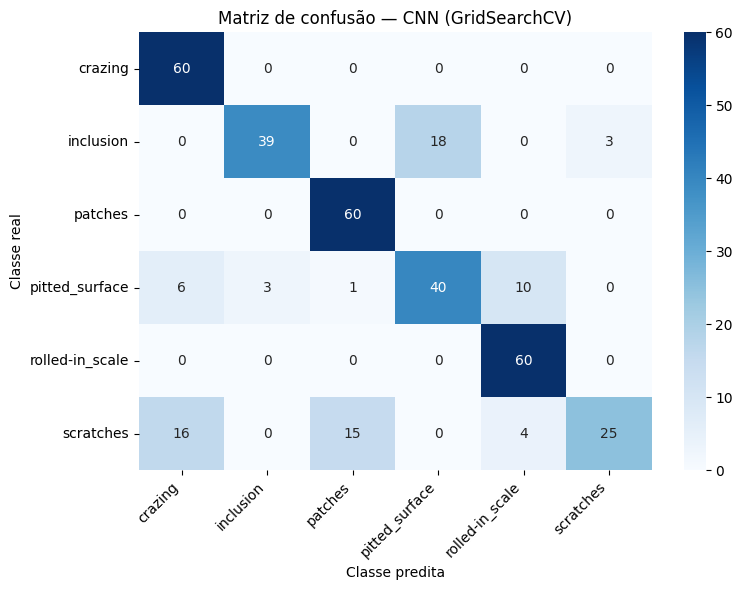

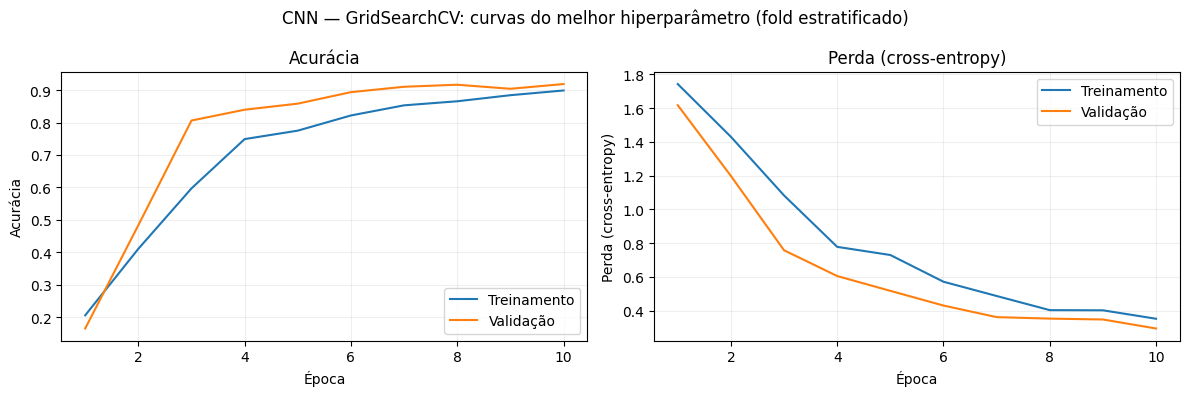

Curvas de um novo ajuste de diagnóstico no primeiro fold estratificado: não são o histórico do modelo final ajustado em todos os dados de treino.


In [ ]:
# ============================================================
# CNN — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_cnn = avaliar_selecionado(
    "CNN", "CNN", X_teste_cnn, usar_probabilidades=True
)
plotar_curvas_keras_escolhido("CNN")

### 5.2 MLP com TensorFlow/Keras e SciKeras

Entrada: atributos HOG das imagens 64×64. `StandardScaler` é aplicado dentro do `Pipeline`; número de camadas, neurônios, dropout e taxa de aprendizagem são parâmetros de arquitetura ou treinamento.

In [ ]:
# ============================================================
# 2A. MLP — KerasClassifier/SciKeras + GridSearchCV + Optuna
# Usa HOG; o StandardScaler fica dentro do Pipeline para ser
# ajustado apenas com os dados de treino de cada fold.
# ============================================================
def build_mlp_model(meta, hidden_units=128, n_hidden_layers=2,
                    activation="relu", dropout_rate=0.2,
                    learning_rate=0.001):
    input_dim = meta["n_features_in_"]
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for _ in range(n_hidden_layers):
        model.add(Dense(hidden_units, activation=activation))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))
    model.add(Dense(num_classes, activation="softmax"))
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

mlp_keras = KerasClassifier(
    model=build_mlp_model,
    verbose=0,
    random_state=SEED
)
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", mlp_keras)
])

param_grid_mlp = {
    "mlp__model__hidden_units": [64, 128],
    "mlp__model__n_hidden_layers": [1, 2],
    "mlp__model__activation": ["relu"],
    "mlp__model__dropout_rate": [0.0, 0.2],
    "mlp__model__learning_rate": [0.001],
    "mlp__batch_size": [16],
    "mlp__epochs": [15]
}

def sugerir_mlp(trial):
    return {
        "mlp__model__hidden_units": trial.suggest_categorical("mlp__model__hidden_units", [64, 128, 256]),
        "mlp__model__n_hidden_layers": trial.suggest_int("mlp__model__n_hidden_layers", 1, 3),
        "mlp__model__activation": trial.suggest_categorical("mlp__model__activation", ["relu", "tanh"]),
        "mlp__model__dropout_rate": trial.suggest_float("mlp__model__dropout_rate", 0.0, 0.4),
        "mlp__model__learning_rate": trial.suggest_float("mlp__model__learning_rate", 1e-4, 1e-2, log=True),
        "mlp__batch_size": trial.suggest_categorical("mlp__batch_size", [16, 32]),
        "mlp__epochs": trial.suggest_categorical("mlp__epochs", [15, 20, 30])
    }

resultados_busca["MLP"] = executar_buscas(
    "MLP", mlp_pipeline, param_grid_mlp, sugerir_mlp,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_mlp = resultados_busca["MLP"]["modelo_gs"]
best_model_optuna_mlp = resultados_busca["MLP"]["modelo_optuna"]


MLP: GridSearchCV
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Melhor acurácia média CV (GS): 0.8611
Melhores parâmetros GS: {'mlp__batch_size': 16, 'mlp__epochs': 15, 'mlp__model__activation': 'relu', 'mlp__model__dropout_rate': 0.0, 'mlp__model__hidden_units': 128, 'mlp__model__learning_rate': 0.001, 'mlp__model__n_hidden_layers': 2}
Tempo GS (incluindo refit): 1.75 min

MLP: Optuna (10 trials)
Melhor acurácia média CV (Optuna): 0.8701
Melhores parâmetros Optuna: {'mlp__model__hidden_units': 128, 'mlp__model__n_hidden_layers': 3, 'mlp__model__activation': 'relu', 'mlp__model__dropout_rate': 0.044020769811070705, 'mlp__model__learning_rate': 0.000285673742984719, 'mlp__batch_size': 32, 'mlp__epochs': 15}
Tempo Optuna (incluindo refit): 3.64 min



MLP: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,MLP,GridSearchCV,0.8611,0.0123,0.8619,1.75,8,24,"{'mlp__batch_size': 16, 'mlp__epochs': 15, 'mlp__model__activation': 'relu', 'mlp__model__dropout_rate': 0.0, 'mlp__model__hidden_units': 128, 'mlp__model__learning_rate': 0.001, 'mlp__model__n_hidden_layers': 2}"
1,MLP,Optuna,0.8701,0.0217,0.8693,3.64,10,30,"{'mlp__model__hidden_units': 128, 'mlp__model__n_hidden_layers': 3, 'mlp__model__activation': 'relu', 'mlp__model__dropout_rate': 0.044020769811070705, 'mlp__model__learning_rate': 0.000285673742984719, 'mlp__batch_size': 32, 'mlp__epochs': 15}"


ESCOLHIDO: Optuna. Justificativa: Maior acurácia CV (diferença de 0.90 p.p.).
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nMLP — Optuna
Acurácia: 0.8833 | Precisão macro: 0.8867 | Recall macro: 0.8833 | F1 macro: 0.8798 | F1 ponderado: 0.8798
\nRelatório de classificação:
                 precision    recall  f1-score   support

        crazing       0.77      0.92      0.84        60
      inclusion       0.95      0.87      0.90        60
        patches       0.87      0.90      0.89        60
 pitted_surface       0.88      0.63      0.74        60
rolled-in_scale       0.94      0.98      0.96        60
      scratches       0.91      1.00      0.95        60

       accuracy                           0.88       360
      macro avg       0.89      0.88      0.88       360
   weighted avg       0.89      0.88      0.88       360



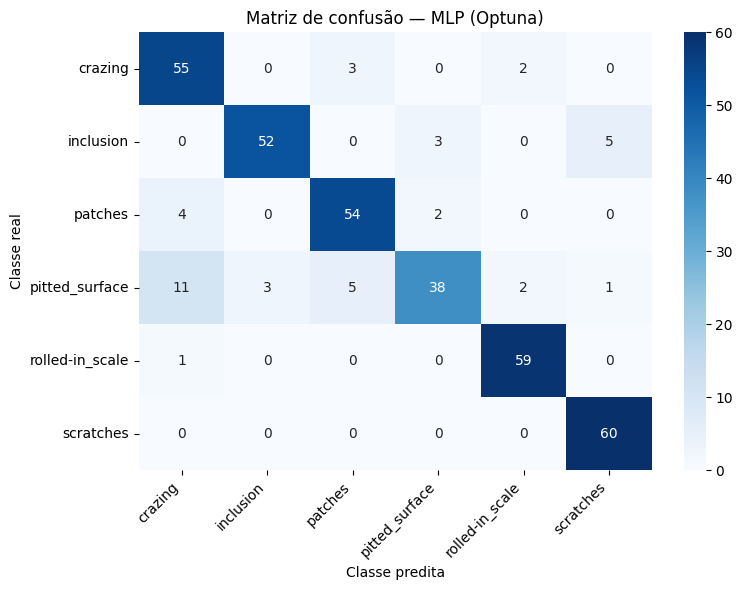

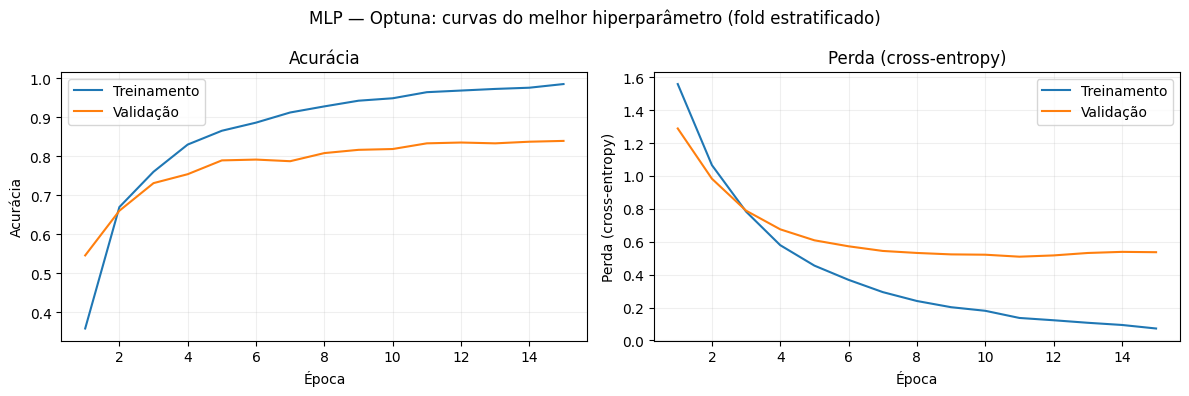

Curvas de um novo ajuste de diagnóstico no primeiro fold estratificado: não são o histórico do modelo final ajustado em todos os dados de treino.


In [ ]:
# ============================================================
# MLP — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_mlp = avaliar_selecionado(
    "MLP", "MLP", X_teste_hog_raw, usar_probabilidades=False
)
plotar_curvas_keras_escolhido("MLP")

### 5.3 Random Forest

In [ ]:
# ============================================================
# 3A. Random Forest (RF) — GridSearchCV + Optuna
# Usa os vetores HOG sem escalonamento, apropriado para árvores.
# ============================================================
rf = RandomForestClassifier(random_state=SEED, n_jobs=1)
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}

def sugerir_rf(trial):
    return {
        "n_estimators": trial.suggest_categorical("n_estimators", [100, 200, 300]),
        "max_depth": trial.suggest_categorical("max_depth", [None, 10, 20, 30]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 4),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None])
    }

resultados_busca["RF"] = executar_buscas(
    "Random Forest", rf, param_grid_rf, sugerir_rf,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_rf = resultados_busca["RF"]["modelo_gs"]
best_model_optuna_rf = resultados_busca["RF"]["modelo_optuna"]


Random Forest: GridSearchCV
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Melhor acurácia média CV (GS): 0.8618
Melhores parâmetros GS: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Tempo GS (incluindo refit): 2.34 min

Random Forest: Optuna (10 trials)
Melhor acurácia média CV (Optuna): 0.8618
Melhores parâmetros Optuna: {'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 9, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Tempo Optuna (incluindo refit): 10.17 min



RF: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,RF,GridSearchCV,0.8618,0.0180,0.8601,2.34,16,48,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}"
1,RF,Optuna,0.8618,0.0147,0.8603,10.17,10,30,"{'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 9, 'min_samples_leaf': 1, 'max_features': 'sqrt'}"


ESCOLHIDO: GridSearchCV. Justificativa: Acurácia e F1 macro CV próximas (até 0,5 p.p.); menor tempo total de busca e reajuste final.
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nRandom Forest — GridSearchCV
Acurácia: 0.8444 | Precisão macro: 0.8414 | Recall macro: 0.8444 | F1 macro: 0.8406 | F1 ponderado: 0.8406
\nRelatório de classificação:
                 precision    recall  f1-score   support

        crazing       0.78      0.90      0.84        60
      inclusion       0.93      0.85      0.89        60
        patches       0.82      0.82      0.82        60
 pitted_surface       0.66      0.55      0.60        60
rolled-in_scale       0.90      1.00      0.94        60
      scratches       0.97      0.95      0.96        60

       accuracy                           0.84       360
      macro avg       0.84      0.84      0.84       360
   weighted avg      

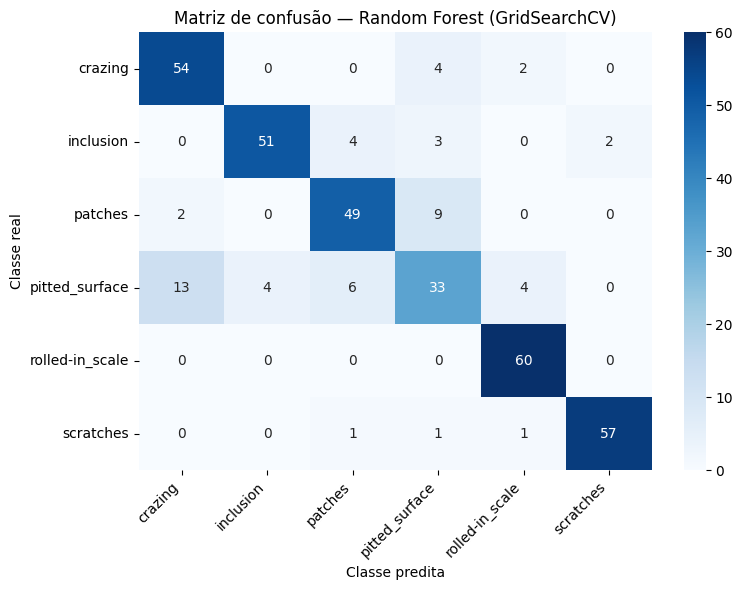

In [ ]:
# ============================================================
# Random Forest — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_rf = avaliar_selecionado(
    "RF", "Random Forest", X_teste_hog_raw, usar_probabilidades=False
)

### 5.4 Árvore de Decisão

In [ ]:
# ============================================================
# 4A. Árvore de Decisão (AD) — GridSearchCV + Optuna
# ============================================================
ad = DecisionTreeClassifier(random_state=SEED)
param_grid_ad = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [None, "sqrt"]
}

def sugerir_ad(trial):
    return {
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
        "max_depth": trial.suggest_categorical("max_depth", [None, 5, 10, 20, 30]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 6),
        "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"])
    }

resultados_busca["AD"] = executar_buscas(
    "Árvore de Decisão", ad, param_grid_ad, sugerir_ad,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_ad = resultados_busca["AD"]["modelo_gs"]
best_model_optuna_ad = resultados_busca["AD"]["modelo_optuna"]


Árvore de Decisão: GridSearchCV
Fitting 3 folds for each of 48 candidates, totalling 144 fits
Melhor acurácia média CV (GS): 0.6194
Melhores parâmetros GS: {'criterion': 'entropy', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Tempo GS (incluindo refit): 0.70 min

Árvore de Decisão: Optuna (10 trials)
Melhor acurácia média CV (Optuna): 0.6160
Melhores parâmetros Optuna: {'criterion': 'log_loss', 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': None}
Tempo Optuna (incluindo refit): 1.10 min



AD: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,AD,GridSearchCV,0.6194,0.0103,0.6187,0.70,48,144,"{'criterion': 'entropy', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}"
1,AD,Optuna,0.6160,0.0136,0.6197,1.10,10,30,"{'criterion': 'log_loss', 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': None}"


ESCOLHIDO: GridSearchCV. Justificativa: Acurácia e F1 macro CV próximas (até 0,5 p.p.); menor tempo total de busca e reajuste final.
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nÁrvore de Decisão — GridSearchCV
Acurácia: 0.5806 | Precisão macro: 0.5817 | Recall macro: 0.5806 | F1 macro: 0.5764 | F1 ponderado: 0.5764
\nRelatório de classificação:
                 precision    recall  f1-score   support

        crazing       0.70      0.70      0.70        60
      inclusion       0.68      0.53      0.60        60
        patches       0.58      0.55      0.56        60
 pitted_surface       0.35      0.33      0.34        60
rolled-in_scale       0.59      0.82      0.69        60
      scratches       0.59      0.55      0.57        60

       accuracy                           0.58       360
      macro avg       0.58      0.58      0.58       360
   weighted avg  

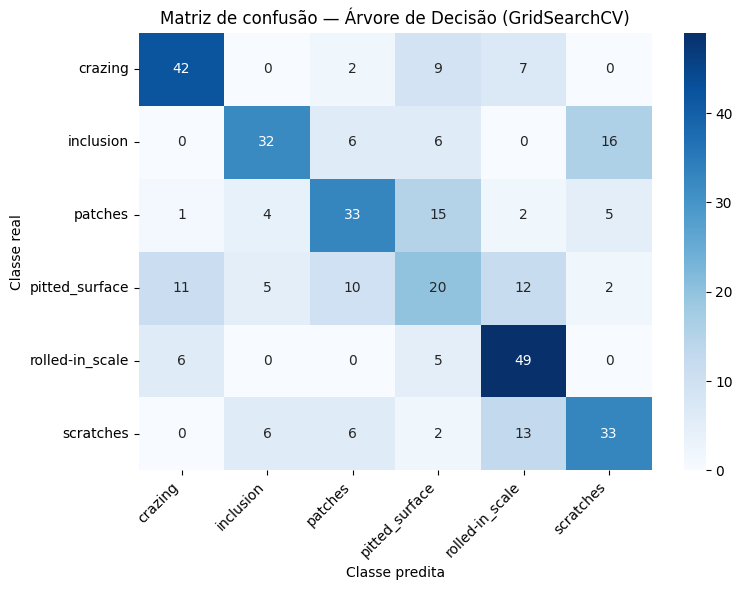

In [ ]:
# ============================================================
# Árvore de Decisão — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_ad = avaliar_selecionado(
    "AD", "Árvore de Decisão", X_teste_hog_raw, usar_probabilidades=False
)

### 5.5 Support Vector Machine (SVM)

In [ ]:
# ============================================================
# 5A. SVM — GridSearchCV + Optuna
# O escalonamento ocorre dentro do Pipeline, em cada fold.
# ============================================================
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])
param_grid_svm = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10], "svm__gamma": ["scale", "auto"]}
]

def sugerir_svm(trial):
    kernel = trial.suggest_categorical("svm__kernel", ["linear", "rbf"])
    params = {
        "svm__kernel": kernel,
        "svm__C": trial.suggest_float("svm__C", 1e-2, 1e2, log=True)
    }
    if kernel == "rbf":
        params["svm__gamma"] = trial.suggest_categorical("svm__gamma", ["scale", "auto"])
    return params

resultados_busca["SVM"] = executar_buscas(
    "SVM", svm_pipeline, param_grid_svm, sugerir_svm,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_svm = resultados_busca["SVM"]["modelo_gs"]
best_model_optuna_svm = resultados_busca["SVM"]["modelo_optuna"]


SVM: GridSearchCV
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Melhor acurácia média CV (GS): 0.8778
Melhores parâmetros GS: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Tempo GS (incluindo refit): 0.07 min

SVM: Optuna (10 trials)
Melhor acurácia média CV (Optuna): 0.8736
Melhores parâmetros Optuna: {'svm__kernel': 'rbf', 'svm__C': 2.342384984711291, 'svm__gamma': 'auto'}
Tempo Optuna (incluindo refit): 1.05 min



SVM: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,SVM,GridSearchCV,0.8778,0.0187,0.8763,0.07,9,27,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}"
1,SVM,Optuna,0.8736,0.0111,0.8730,1.05,10,30,"{'svm__kernel': 'rbf', 'svm__C': 2.342384984711291, 'svm__gamma': 'auto'}"


ESCOLHIDO: GridSearchCV. Justificativa: Acurácia e F1 macro CV próximas (até 0,5 p.p.); menor tempo total de busca e reajuste final.
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nSVM — GridSearchCV
Acurácia: 0.8750 | Precisão macro: 0.8775 | Recall macro: 0.8750 | F1 macro: 0.8706 | F1 ponderado: 0.8706
\nRelatório de classificação:
                 precision    recall  f1-score   support

        crazing       0.75      0.97      0.85        60
      inclusion       0.94      0.83      0.88        60
        patches       0.88      0.88      0.88        60
 pitted_surface       0.80      0.58      0.67        60
rolled-in_scale       0.97      1.00      0.98        60
      scratches       0.92      0.98      0.95        60

       accuracy                           0.88       360
      macro avg       0.88      0.88      0.87       360
   weighted avg       0.88     

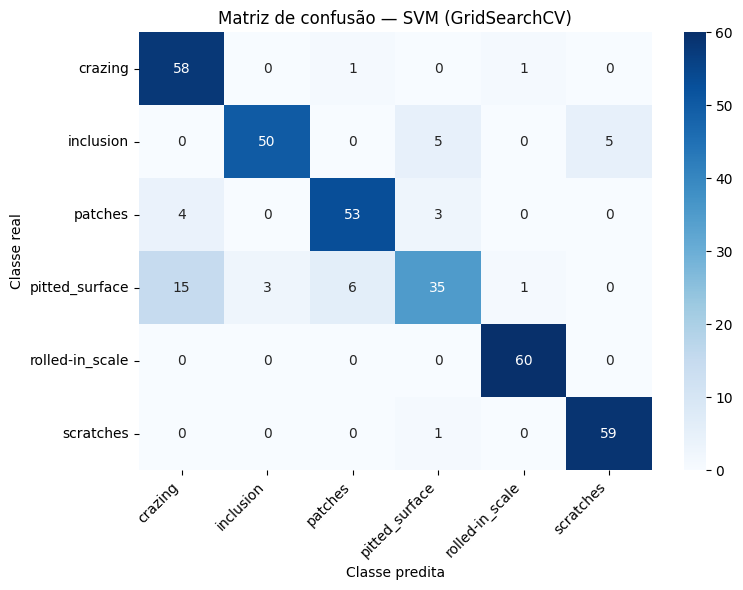

In [ ]:
# ============================================================
# SVM — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_svm = avaliar_selecionado(
    "SVM", "SVM", X_teste_hog_raw, usar_probabilidades=False
)

### 5.6 Gaussian Naive Bayes

In [ ]:
# ============================================================
# 6A. Naive Bayes — GaussianNB + GridSearchCV + Optuna
# GaussianNB é a variante escolhida para vetores HOG contínuos.
# ============================================================
nb = GaussianNB()
param_grid_nb = {
    "var_smoothing": [1e-11, 1e-9, 1e-7]
}

def sugerir_nb(trial):
    return {
        "var_smoothing": trial.suggest_float("var_smoothing", 1e-12, 1e-6, log=True)
    }

resultados_busca["NB"] = executar_buscas(
    "Naive Bayes (GaussianNB)", nb, param_grid_nb, sugerir_nb,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_nb = resultados_busca["NB"]["modelo_gs"]
best_model_optuna_nb = resultados_busca["NB"]["modelo_optuna"]


Naive Bayes (GaussianNB): GridSearchCV
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Melhor acurácia média CV (GS): 0.8167
Melhores parâmetros GS: {'var_smoothing': 1e-11}
Tempo GS (incluindo refit): 0.00 min

Naive Bayes (GaussianNB): Optuna (10 trials)
Melhor acurácia média CV (Optuna): 0.8167
Melhores parâmetros Optuna: {'var_smoothing': 1.7670169402947963e-10}
Tempo Optuna (incluindo refit): 1.06 min



NB: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,NB,GridSearchCV,0.8167,0.0187,0.8124,0.00,3,9,{'var_smoothing': 1e-11}
1,NB,Optuna,0.8167,0.0187,0.8124,1.06,10,30,{'var_smoothing': 1.7670169402947963e-10}


ESCOLHIDO: GridSearchCV. Justificativa: Acurácia e F1 macro CV próximas (até 0,5 p.p.); menor tempo total de busca e reajuste final.
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nNaive Bayes — GridSearchCV
Acurácia: 0.8361 | Precisão macro: 0.8328 | Recall macro: 0.8361 | F1 macro: 0.8293 | F1 ponderado: 0.8293
\nRelatório de classificação:
                 precision    recall  f1-score   support

        crazing       0.73      0.95      0.83        60
      inclusion       0.95      0.88      0.91        60
        patches       0.84      0.78      0.81        60
 pitted_surface       0.64      0.47      0.54        60
rolled-in_scale       0.88      0.95      0.91        60
      scratches       0.97      0.98      0.98        60

       accuracy                           0.84       360
      macro avg       0.83      0.84      0.83       360
   weighted avg       0

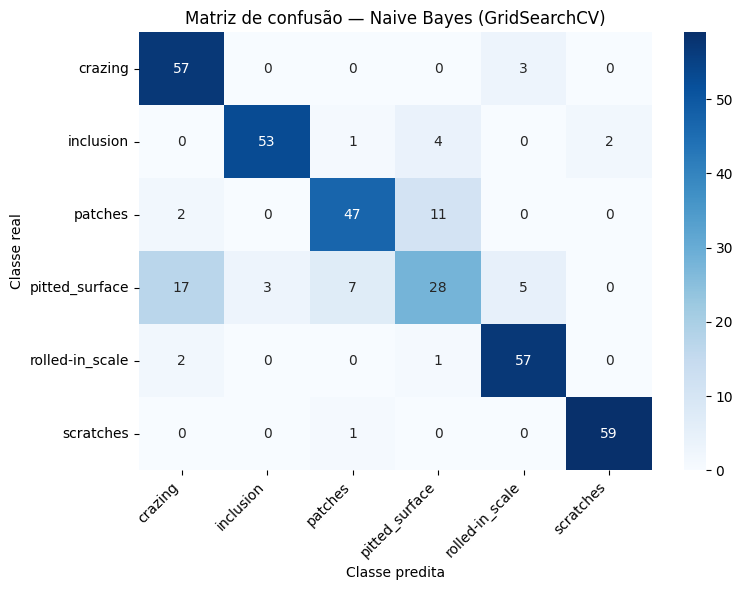

In [ ]:
# ============================================================
# Naive Bayes — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_nb = avaliar_selecionado(
    "NB", "Naive Bayes", X_teste_hog_raw, usar_probabilidades=False
)

## 6. Síntese dos seis classificadores

**Primeiro quadro:** compara o desempenho dos otimizadores (apenas CV dentro de `train/images`). **Segundo quadro:** apresenta os seis modelos escolhidos, agora avaliados em `validation/images` como teste externo. O segundo quadro **não interfere** na escolha de qual otimizador venceu em cada algoritmo.

As conclusões devem levar em conta diferenças nos orçamentos de busca, dispersão da acurácia por fold e o tamanho relativamente pequeno da base.

In [ ]:
# 12 linhas: comparação das ferramentas somente via validação cruzada.
tabela_buscas = pd.DataFrame(comparacoes_buscas).sort_values(["Modelo", "Método"])
display(tabela_buscas)

# 6 linhas: apenas os modelos escolhidos, avaliados uma vez no teste.
tabela_comparacao = pd.DataFrame(resultados_teste).sort_values(
    "F1 macro", ascending=False
).reset_index(drop=True)
display(tabela_comparacao)

# Resumo por modelo: decisão sobre método + desempenho no teste.
print("\nEscolha do otimizador por algoritmo:")
for chave, metodo in metodos_escolhidos.items():
    print(f"- {chave}: {metodo}")

,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
6,AD,GridSearchCV,0.619444,0.010253,0.618748,0.695176,48,144,"{'criterion': 'entropy', 'max_depth': 10, 'max..."
7,AD,Optuna,0.615972,0.013644,0.619657,1.099616,10,30,"{'criterion': 'log_loss', 'max_depth': None, '..."
0,CNN,GridSearchCV,0.902083,0.026571,0.901507,63.344322,16,48,"{'batch_size': 16, 'epochs': 10, 'model__conv_..."
1,CNN,Optuna,0.847917,0.013502,0.846150,76.343142,10,30,"{'batch_size': 16, 'epochs': 10, 'model__conv_..."
2,MLP,GridSearchCV,0.861111,0.012306,0.861854,1.752765,8,24,"{'mlp__batch_size': 16, 'mlp__epochs': 15, 'ml..."
3,MLP,Optuna,0.870139,0.021673,0.869269,3.641397,10,30,"{'mlp__model__hidden_units': 128, 'mlp__model_..."
10,NB,GridSearchCV,0.816667,0.018711,0.812439,0.001877,3,9,{'var_smoothing': 1e-11}
11,NB,Optuna,0.816667,0.018711,0.812439,1.062831,10,30,{'var_smoothing': 1.7670169402947963e-10}
4,RF,GridSearchCV,0.861806,0.018029,0.860107,2.343230,16,48,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
5,RF,Optuna,0.861806,0.014666,0.860269,10.172390,10,30,"{'n_estimators': 300, 'max_depth': 20, 'min_sa..."


,Modelo,Busca,Acurácia teste,Precisão macro,Recall macro,F1 macro,F1 ponderado
0,MLP,Optuna,0.883333,0.886732,0.883333,0.879814,0.879814
1,SVM,GridSearchCV,0.875000,0.877508,0.875000,0.870550,0.870550
2,Random Forest,GridSearchCV,0.844444,0.841362,0.844444,0.840616,0.840616
3,Naive Bayes,GridSearchCV,0.836111,0.832831,0.836111,0.829316,0.829316
4,CNN,GridSearchCV,0.788889,0.807179,0.788889,0.772300,0.772300
5,Árvore de Decisão,GridSearchCV,0.580556,0.581720,0.580556,0.576399,0.576399



Escolha do otimizador por algoritmo:
- CNN: GridSearchCV
- MLP: Optuna
- RF: GridSearchCV
- AD: GridSearchCV
- SVM: GridSearchCV
- NB: GridSearchCV


## 7. Notas metodológicas para o relatório

1. **Partição original:** treino em `train/images` e teste final em `validation/images`. O conjunto chamado "validation" pelo Kaggle **não** é usado na otimização de hiperparâmetros.
2. **Pré-processamento:** leitura em escala de cinza, normalização em [0,1], redimensionamento para 64×64, extração de HOG para os cinco modelos não CNN. O escalonamento de HOG para MLP e SVM é ajustado **dentro** de cada fold.
3. **Validação cruzada:** `StratifiedKFold` com `N_SPLITS=3`, embaralhamento e semente 42. O dataset atual contém uma imagem por observação — não se usa `StratifiedGroupKFold`, que era necessário no Dataset 1 por causa dos recortes da mesma imagem de origem.
4. **Seleção do otimizador:** acurácia CV prioritária; F1 macro CV como desempate; tempo total quando as métricas estão próximas. O tempo inclui o treinamento final com os hiperparâmetros vencedores.
5. **Sem poda (*pruning*):** Optuna completa os três folds de cada tentativa. Isso torna a comparação do protocolo de CV diretamente interpretável.
6. **Gráficos de CNN e MLP:** curvas geradas em um novo treinamento de **diagnóstico** usando um fold interno, sem acesso ao teste. Podem diferir do histórico do modelo final treinado no conjunto completo.
7. **Balanceamento:** confirme o balanceamento pelos números impressos; não pressuponha que as pastas tenham exatamente as contagens descritas na fonte sem verificar.

**Limitação:** não há garantia de execução completa no ambiente de criação deste arquivo, pois as imagens do Kaggle e o TensorFlow não estão disponíveis aqui. Os resultados experimentais reais devem ser produzidos ao executar o notebook no Kaggle com o dataset conectado.